# 零售门店销售与利润分析

基于 **5.1 万条**全球零售订单数据（2011-2014），分析销售额与利润，
识别利润流失原因并给出优化方案。


## 1. 数据入库

读入 CSV（latin-1 编码），统一日期格式（斜杠/横杠混用），存入 SQLite。

In [27]:
import pandas as pd
import sqlite3
df=pd.read_csv("E:/learn Python/superstore/superstore_dataset2011-2015.csv",encoding="latin-1")
df["Order Date"]=df["Order Date"].str.replace("-","/",regex=False)
df["Ship Date"]=df["Ship Date"].str.replace("-","/",regex=False)
df["Order Date"]=pd.to_datetime(df["Order Date"],format="%d/%m/%Y")
df["Ship Date"]=pd.to_datetime(df["Ship Date"],format="%d/%m/%Y")
conn=sqlite3.connect("E:/learn Python/superstore/superstore.db")
df.to_sql("orders",conn,if_exists="replace",index=False)

51290

## 2. 折扣与利润：30% 红线 ⭐

按折扣区间统计平均利润。**0-30% 盈利，30% 以上开始亏损**。

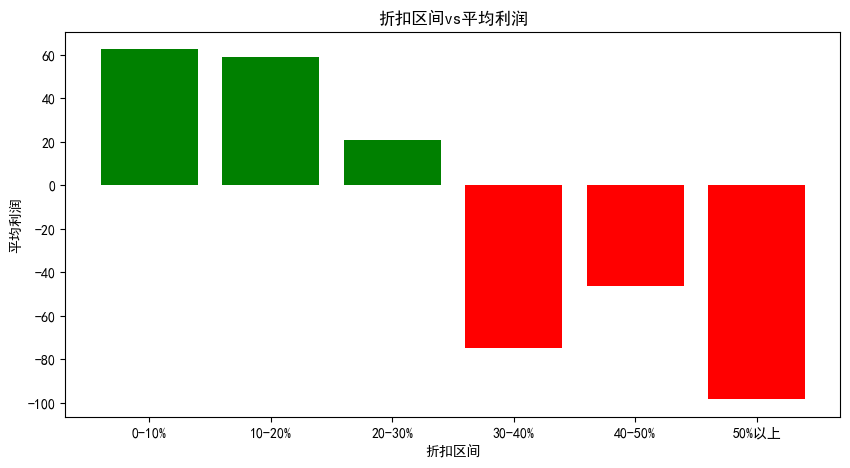

In [11]:
import matplotlib.pyplot as plt
plt.rcParams["font.sans-serif"]=["SimHei"]
plt.rcParams["axes.unicode_minus"]=False
conn=sqlite3.connect("E:/learn Python/superstore/superstore.db")
df=pd.read_sql("""select case when "Discount" <0.1 then '0-10%'
                              when "Discount" <0.2 then '10-20%'
                              when "Discount" <0.3 then '20-30%'
                              when "Discount" <0.4 then '30-40%'
                              when "Discount" <0.5 then '40-50%'
                              else '50%以上' end as 折扣区间,
                round(avg("Profit"),2) as 平均利润 from orders 
                group by 折扣区间 order by 折扣区间;    """,conn)
colors=["green" if v>0 else "red" for v in df["平均利润"]]
plt.figure(figsize=(10,5))
plt.bar(df["折扣区间"],df["平均利润"],color=colors)
plt.ylabel("平均利润")
plt.xlabel("折扣区间")
plt.title("折扣区间vs平均利润")
plt.savefig("E:/learn Python/superstore/超市_折扣利润.png")
plt.show()

## 3. 年度趋势

4 年销售额与利润双轴趋势图，两项均翻倍增长。

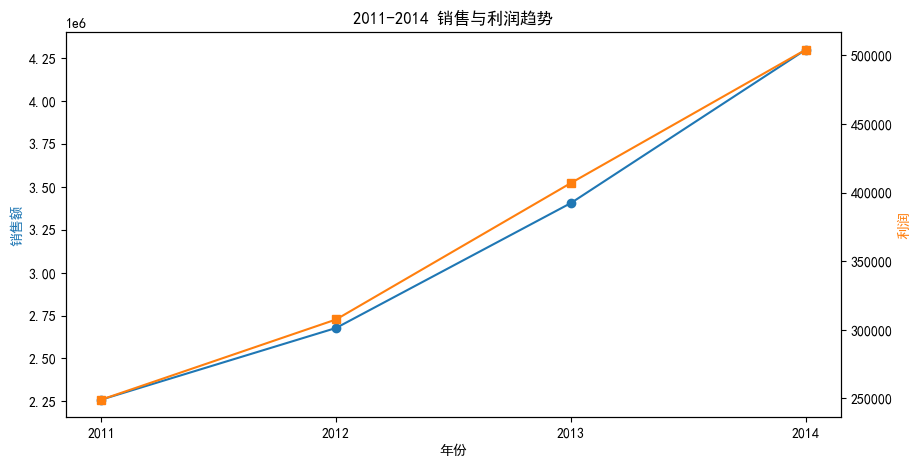

In [18]:
df=pd.read_sql("""select strftime('%Y',"Order Date") as 年份,
                sum("Sales") as 销售额,
                sum("Profit") as 利润
                from orders group by 年份 order by 年份;""",conn)
fig,ax1=plt.subplots(figsize=(10,5))
ax1.plot(df["年份"],df["销售额"],marker="o",color="tab:blue",label="销售额")
ax1.set_ylabel("销售额",color="tab:blue")
ax2=ax1.twinx()
ax2.plot(df["年份"],df["利润"],marker="s",color="tab:orange",label="利润")
ax2.set_ylabel("利润",color="tab:orange")
ax1.set_xlabel("年份")
plt.title("2011-2014 销售与利润趋势")
plt.savefig("E:/learn Python/superstore/超市_年度趋势.png")

## 4. 敏感性分析

不同折扣上限方案能挽回的利润：折扣越严，挽回越多，但客户流失风险也越大。

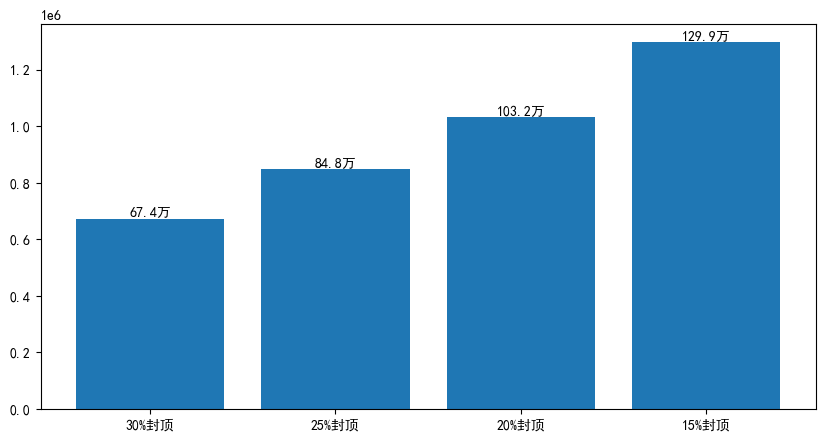

In [20]:
方案=["30%封顶","25%封顶","20%封顶","15%封顶"]
可挽回=[673685,848295,1032488,1298858]
plt.figure(figsize=(10,5))
plt.bar(方案,可挽回)
for i,v in enumerate(可挽回):
    plt.text(i,v,f"{v/10000:.1f}万",ha="center",va="bottom")
plt.savefig("E:/learn Python/superstore/超市_敏感性分析.png")
plt.show()

## 5. 子类目利润 ⭐

17 个子类目的利润排名。**Tables（桌子）是唯一亏损的子类目**。

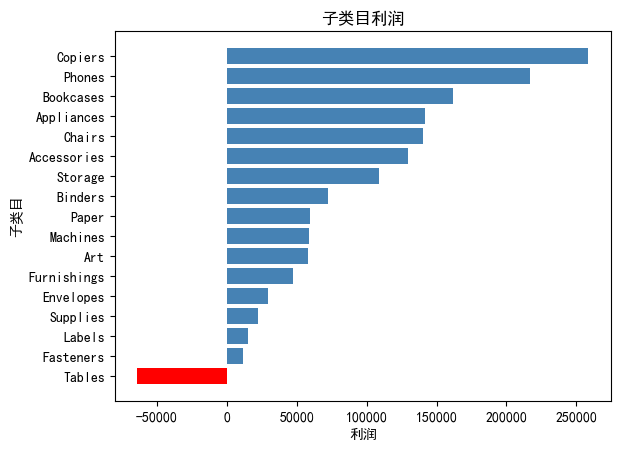

In [22]:
df=pd.read_sql("""select "Sub-Category" as 子类目,sum("Profit") as 利润
                from orders group by "Sub-Category" order by 利润;""",conn)
colors=["red" if v < 0 else "steelblue" for v in df["利润"]]
plt.barh(df["子类目"],df["利润"],color=colors)
plt.xlabel("利润")
plt.ylabel("子类目")
plt.title("子类目利润")
plt.savefig("E:/learn Python/superstore/超市_子类目利润.png")
plt.show()

## 6. 客户帕累托

客户累计占比 vs 利润累计占比。**29.4% 的客户贡献了 80% 的利润**。

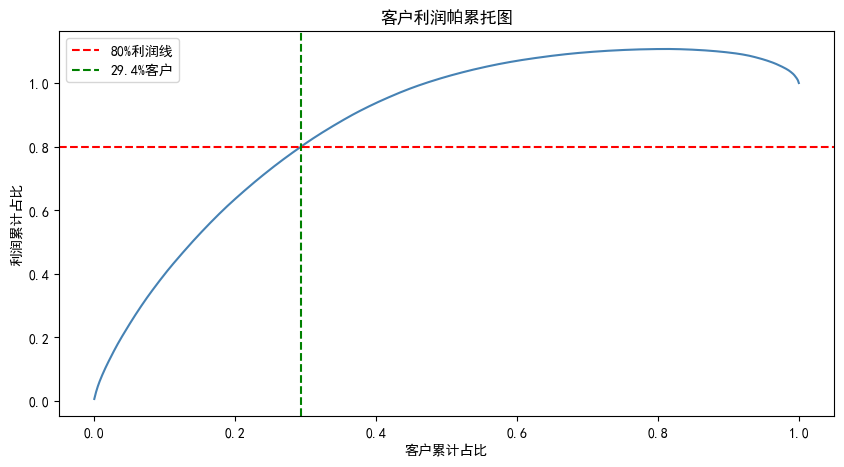

In [23]:
df=pd.read_sql(""" select "Customer ID",sum("Profit") as 利润
                from orders group by "Customer ID" order by 利润 desc;""",conn)
df["累计利润"]=df["利润"].cumsum()
df["客户占比"]=(df.index+1)/len(df)
df["利润占比"]=df["累计利润"]/df["利润"].sum()
plt.figure(figsize=(10,5))
plt.plot(df["客户占比"],df["利润占比"],color="steelblue")
plt.axhline(0.8,color="red",linestyle="--",label="80%利润线")
plt.axvline(0.294,color="green",linestyle="--",label="29.4%客户")
plt.xlabel("客户累计占比")
plt.ylabel("利润累计占比")
plt.title("客户利润帕累托图")
plt.legend()
plt.savefig("E:/learn Python/superstore/超市_客户帕累托.png")

## 7. 导出数据（供 Power BI）

把聚合结果导出为 CSV，用于 Power BI 仪表板。

In [30]:
df=pd.read_sql("""select case when "Discount" <0.1 then '0-10%'
                              when "Discount" <0.2 then '10-20%'
                              when "Discount" <0.3 then '20-30%'
                              when "Discount" <0.4 then '30-40%'
                              when "Discount" <0.5 then '40-50%'
                              else '50%以上' end as 折扣区间,
                round(avg("Profit"),2) as 平均利润 from orders 
                group by 折扣区间 order by 折扣区间;    """,conn)
df.to_csv("E:/learn Python/superstore/bi/折扣利润.csv",index=False,encoding="utf-8-sig")
df=pd.read_sql("""select strftime('%Y',"Order Date") as 年份,
                sum("Sales") as 销售额,
                sum("Profit") as 利润
                from orders group by 年份 order by 年份;""",conn)
df.to_csv("E:/learn Python/superstore/bi/年度趋势.csv",index=False,encoding="utf-8-sig")
df=pd.read_sql("""select "Sub-Category" as 子类目,sum("Profit") as 利润
                from orders group by "Sub-Category" order by 利润;""",conn)
df.to_csv("E:/learn Python/superstore/bi/子类目利润.csv",index=False,encoding="utf-8-sig")
df = pd.read_sql("""SELECT strftime('%m', "Order Date") AS 月份,
                           SUM("Sales") AS 销售额
                    FROM orders GROUP BY 月份 ORDER BY 月份;""", conn)
df.to_csv("E:/learn Python/superstore/bi/月度季节.csv", index=False, encoding="utf-8-sig")
df = pd.read_sql("""SELECT "Customer ID" AS 客户, SUM("Profit") AS 利润
                    FROM orders GROUP BY "Customer ID" ORDER BY 利润 DESC;""", conn)
df.to_csv("E:/learn Python/superstore/bi/客户利润.csv", index=False, encoding="utf-8-sig")
df = pd.read_sql('SELECT COUNT(DISTINCT "Order ID") AS 订单数 FROM orders;', conn)
df.to_csv("E:/learn Python/superstore/bi/订单数.csv", index=False, encoding="utf-8-sig")
conn.close()